III.) Data visualization

PFC miRNA and mRNA expression regressions

We use all 27 processed PFC miRNA profiles and all selected postnatal samples from our cleaned PFC mRNA dataset. The two datasets are analyzed separately; we do not need to match individuals.

The miRNA file already contains one normalized profile per individual. Technical miRNA array replicates were combined during the original data processing and must not be averaged again.

The age adjustment approximates macaque-equivalent developmental age:

$$
a_{\mathrm{adjusted}} =
\begin{cases}
\frac{33}{98}a, & \mathrm{human},\\
\frac{30}{44}a, & \mathrm{chimpanzee},\\
a, & \mathrm{macaque}.
\end{cases}
$$

For each miRNA or mRNA gene, we fit a separate ordinary least-squares regression for each species:

$$
\mathrm{expression}=c_0+c_1\log_2(a_{\mathrm{adjusted}}+1).
$$

The expression values are already normalized and log2-transformed in the input CSVs. The notebook creates one 3-by-3 plot for nine random miRNAs and one for nine random mRNA genes. All files are loaded locally.

1.) Read the expression and sample information files.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

mirna_expr = pd.read_csv("results/pfc_mirna_expression.csv", index_col=0)
mirna_info = pd.read_csv("results/pfc_mirna_sample_info.csv").set_index("Sample")

mrna_expr = pd.read_csv("results/pfc_mrna_gene_expression.csv", index_col="Gene")
mrna_info = pd.read_csv("results/pfc_mrna_sample_info.csv").set_index("GSM")

print("miRNA expression matrix:", mirna_expr.shape)
print("mRNA expression matrix:", mrna_expr.shape)

miRNA expression matrix: (198, 27)
mRNA expression matrix: (11667, 58)


2.) Select the miRNA profiles and mRNA samples. 

In [2]:
species_names = {
    "human": "Human", "hsa": "Human",
    "chimp": "Chimpanzee", "chimpanzee": "Chimpanzee", "ptr": "Chimpanzee",
    "macaque": "Macaque", "rhesus macaque": "Macaque", "mml": "Macaque",
}

age_factors = {"Human": 33 / 98, "Chimpanzee": 30 / 44, "Macaque": 1.0}
species_order = ["Human", "Chimpanzee", "Macaque"]

# Processed miRNA samples: all 27 biological profiles, including the 45-day chimpanzee.
mirna_info = mirna_info.loc[mirna_expr.columns].copy()
mirna_info["Species"] = mirna_info["Species"].str.strip().str.lower().map(species_names)
mirna_info["Age_days"] = pd.to_numeric(mirna_info["Original_age_days"])

# Cleaned mRNA file: use every available sample, independently of the miRNA data.
mrna_info = mrna_info.loc[mrna_expr.columns].copy()
mrna_info["Species"] = mrna_info["Species"].str.strip().str.lower().map(species_names)
mrna_info["Age_days"] = pd.to_numeric(mrna_info["Age_days"])

# The logarithmic age model is fitted only to postnatal observations.
mrna_info = mrna_info[mrna_info["Age_days"] >= 0].copy()
mrna_expr = mrna_expr[mrna_info.index].copy()

mirna_info["x"] = np.log2(
    mirna_info["Age_days"] * mirna_info["Species"].map(age_factors) + 1
)
mrna_info["x"] = np.log2(
    mrna_info["Age_days"] * mrna_info["Species"].map(age_factors) + 1
)

counts = pd.DataFrame({
    "miRNA": mirna_info["Species"].value_counts(),
    "mRNA": mrna_info["Species"].value_counts(),
}).reindex(species_order).fillna(0).astype(int)
print("Selected profiles:")
display(counts)

Selected profiles:


,miRNA,mRNA
Species,,
Human,8,21
Chimpanzee,11,12
Macaque,8,25


3.) Select nine random miRNAs and nine random mRNA genes. The random seed makes the choice reproducible.

In [3]:
rng = np.random.default_rng(42)
selected_mirnas = rng.choice(mirna_expr.index, 9, replace=False)
selected_mrnas = rng.choice(mrna_expr.index, 9, replace=False)

print("Selected miRNAs:", ", ".join(selected_mirnas))
print("Selected mRNA genes:", ", ".join(selected_mrnas))

Selected miRNAs: hsa-mir-137, hsa-mir-410, hsa-mir-543, hsa-mir-342-3p, hsa-mir-218, hsa-mir-376a, hsa-mir-98, hsa-mir-940, hsa-mir-1202
Selected mRNA genes: XPO6, PARK2, GDF9, ZWINT, EML3, ATP8B1, EXOG, ANXA1, ZNF780A


4.) Fit the three regression lines and plot the original expression measurements.

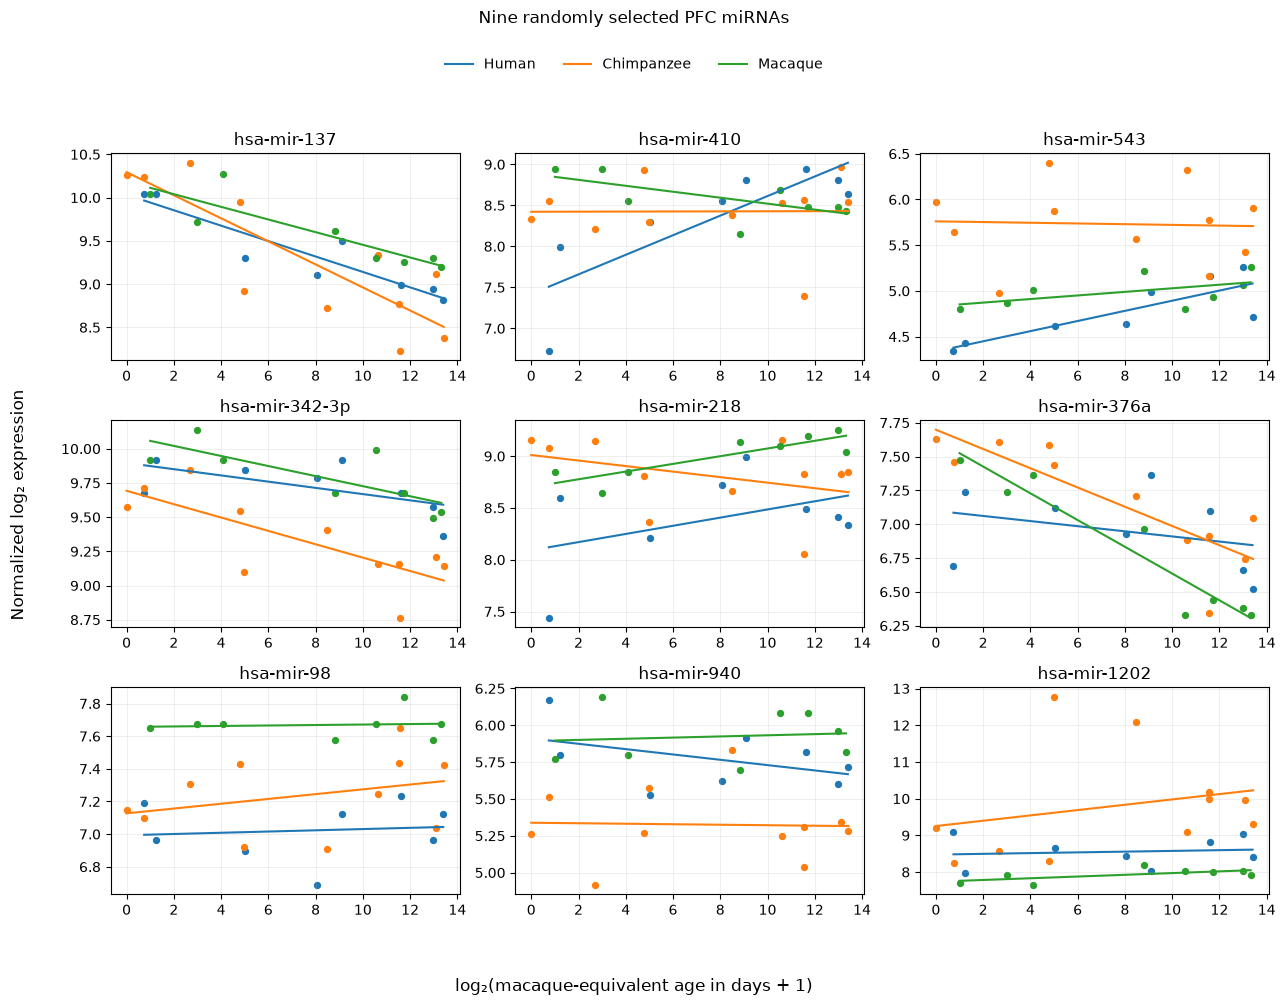

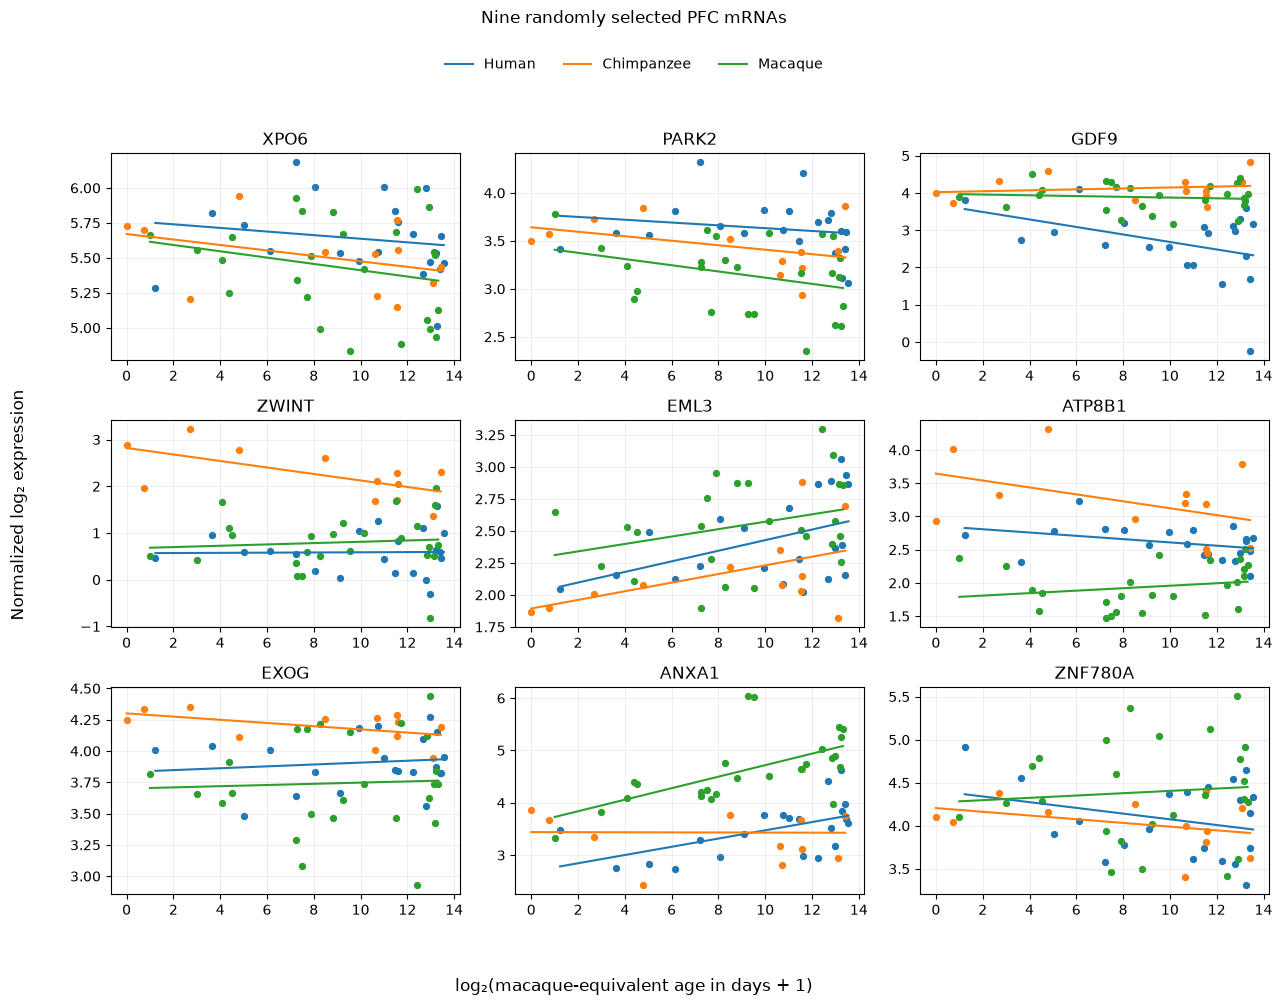

In [4]:
def plot_nine_regressions(expression, sample_info, features, label):
    fig, axes = plt.subplots(3, 3, figsize=(13, 10))
    results = []

    for ax, feature in zip(axes.flat, features):
        for species in species_order:
            samples = sample_info.index[sample_info["Species"] == species]
            x = sample_info.loc[samples, "x"].to_numpy(dtype=float)
            y = pd.to_numeric(expression.loc[feature, samples], errors="coerce").to_numpy(dtype=float)
            valid = np.isfinite(x) & np.isfinite(y)
            x, y = x[valid], y[valid]

            if len(x) < 2 or len(np.unique(x)) < 2:
                continue

            c1, c0 = np.polyfit(x, y, 1)
            y_fit = c0 + c1 * x
            ss_total = np.sum((y - y.mean()) ** 2)
            r2 = np.nan if ss_total == 0 else 1 - np.sum((y - y_fit) ** 2) / ss_total

            results.append({"Feature": feature, "Species": species,
                            "n": len(x), "c0": c0, "c1": c1, "R2": r2})

            line_x = np.linspace(x.min(), x.max(), 100)
            line, = ax.plot(line_x, c0 + c1 * line_x, label=species)
            ax.scatter(x, y, color=line.get_color(), s=18)

        ax.set_title(str(feature))
        ax.grid(alpha=0.2)

    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.96),
               ncol=3, frameon=False)
    fig.supxlabel("log₂(macaque-equivalent age in days + 1)")
    fig.supylabel("Normalized log₂ expression")
    fig.suptitle("Nine randomly selected PFC " + label + "s", y=0.995)
    fig.tight_layout(rect=[0.03, 0.04, 1, 0.92])
    fig.savefig(f"results/pfc_{label.lower()}_random_regressions.png", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    return fig, pd.DataFrame(results)

mirna_fig, mirna_fits = plot_nine_regressions(
    mirna_expr, mirna_info, selected_mirnas, "miRNA"
)

mrna_fig, mrna_fits = plot_nine_regressions(
    mrna_expr, mrna_info, selected_mrnas, "mRNA"
)



Regression coefficients and fit quality.

In [5]:
print("miRNA regressions")
display(mirna_fits.round(4))

print("mRNA regressions")
display(mrna_fits.round(4))

miRNA regressions


,Feature,Species,n,c0,c1,R2
0,hsa-mir-137,Human,8,10.0321,-0.0891,0.8615
1,hsa-mir-137,Chimpanzee,11,10.2936,-0.1332,0.7086
2,hsa-mir-137,Macaque,8,10.1857,-0.0732,0.7781
3,hsa-mir-410,Human,8,7.4191,0.1194,0.6788
4,hsa-mir-410,Chimpanzee,11,8.4218,0.0006,0.0001
5,hsa-mir-410,Macaque,8,8.8836,-0.0363,0.4325
6,hsa-mir-543,Human,8,4.3385,0.0554,0.6772
7,hsa-mir-543,Chimpanzee,11,5.7606,-0.0039,0.0019
8,hsa-mir-543,Macaque,8,4.8330,0.0196,0.2829
9,hsa-mir-342-3p,Human,8,9.8961,-0.0228,0.3600


mRNA regressions


,Feature,Species,n,c0,c1,R2
0,XPO6,Human,21,5.7655,-0.0129,0.0280
1,XPO6,Chimpanzee,12,5.6702,-0.0196,0.1469
2,XPO6,Macaque,25,5.6372,-0.0226,0.0556
3,PARK2,Human,21,3.7788,-0.0146,0.0326
4,PARK2,Chimpanzee,12,3.6415,-0.0234,0.1634
5,PARK2,Macaque,25,3.4401,-0.0324,0.1000
6,GDF9,Human,21,3.6917,-0.1006,0.1539
7,GDF9,Chimpanzee,12,4.0218,0.0125,0.0306
8,GDF9,Macaque,25,3.9781,-0.0101,0.0099
9,ZWINT,Human,21,0.5665,0.0020,0.0002
